# T26: detectability ceiling — figures
Regenerates every README figure from `data/` (no drive or runs needed). Heavy work is in `tools/audit/detectability.py` (per-star statistic, reads the T20 stacks on the drive) and `tools/audit/detectability_analysis.py prepare` (joins to the T10 dev_medium runs, threshold scan, metrics, example light curves).

In [1]:
import sys, json
from pathlib import Path
REPO = Path.cwd()
while not (REPO / 'tools').is_dir(): REPO = REPO.parent
sys.path.insert(0, str(REPO / 'tools' / 'audit'))
import detectability_analysis as A
import pandas as pd
from IPython.display import Image, display
THR = json.loads((A.REPORT / 'metrics.json').read_text())['threshold']
A.make_figures(THR)
J = A.load_joined(); THR

5.0

## Which statistic: AUC for predicting pipeline success

In [2]:
A.auc_table(J).round(3)

,fullyear,assigned
D_band·√N_cyc (chosen),0.865,0.879
D_peak (LS peak S/N),0.874,0.838
D_band,0.824,0.755
injected RMS only,0.838,0.786
catalog amp proxy (T1),0.812,0.795
noise RMS only,0.441,0.396


## Detectability vs the catalog amplitude proxy (T1)

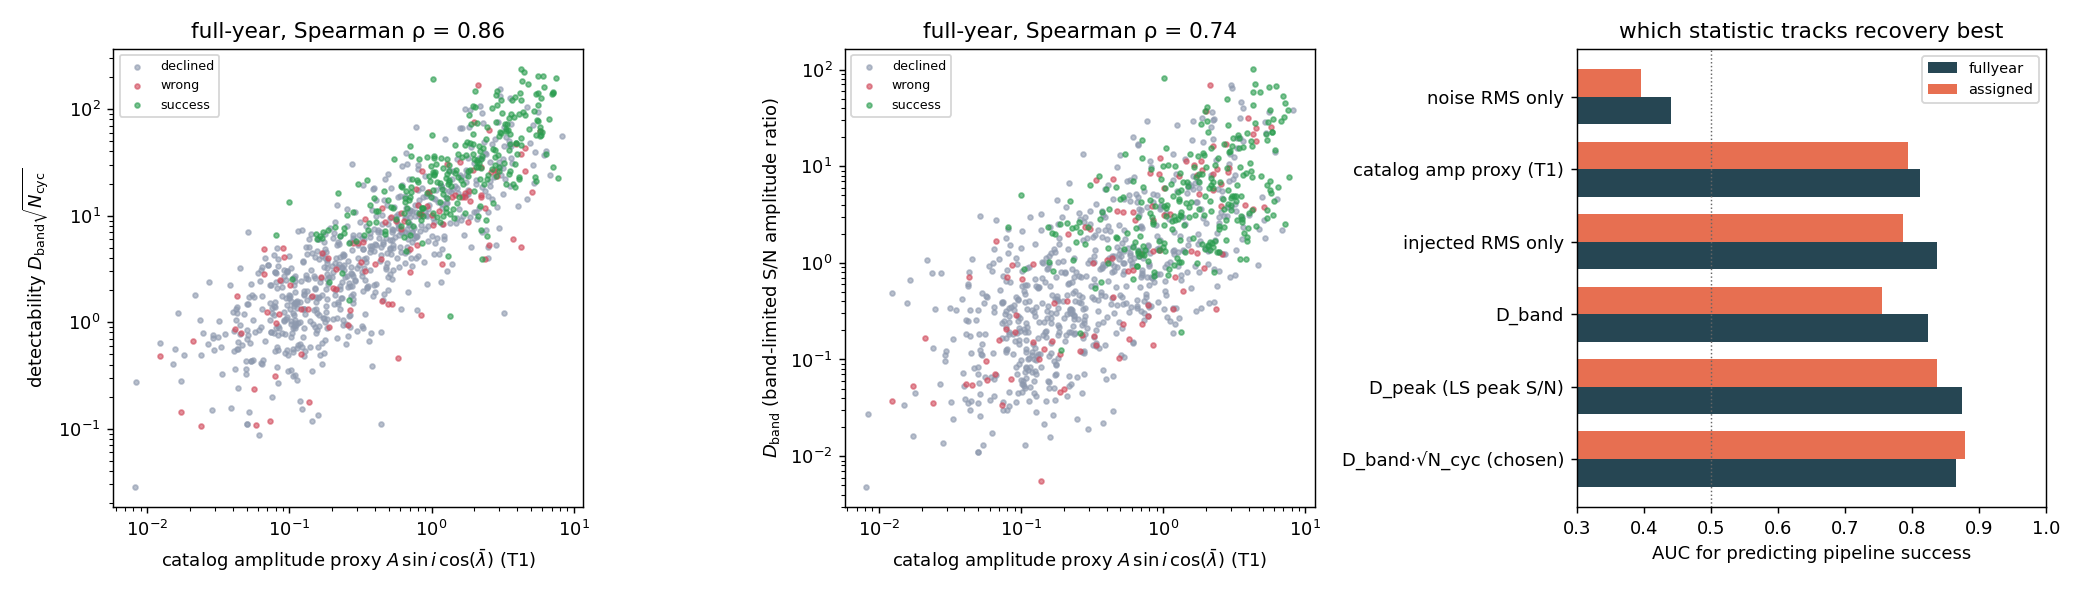

In [3]:
display(Image(A.FIG / 'detectability_vs_amp_proxy.png'))

## Distribution per period bin, both coverage modes

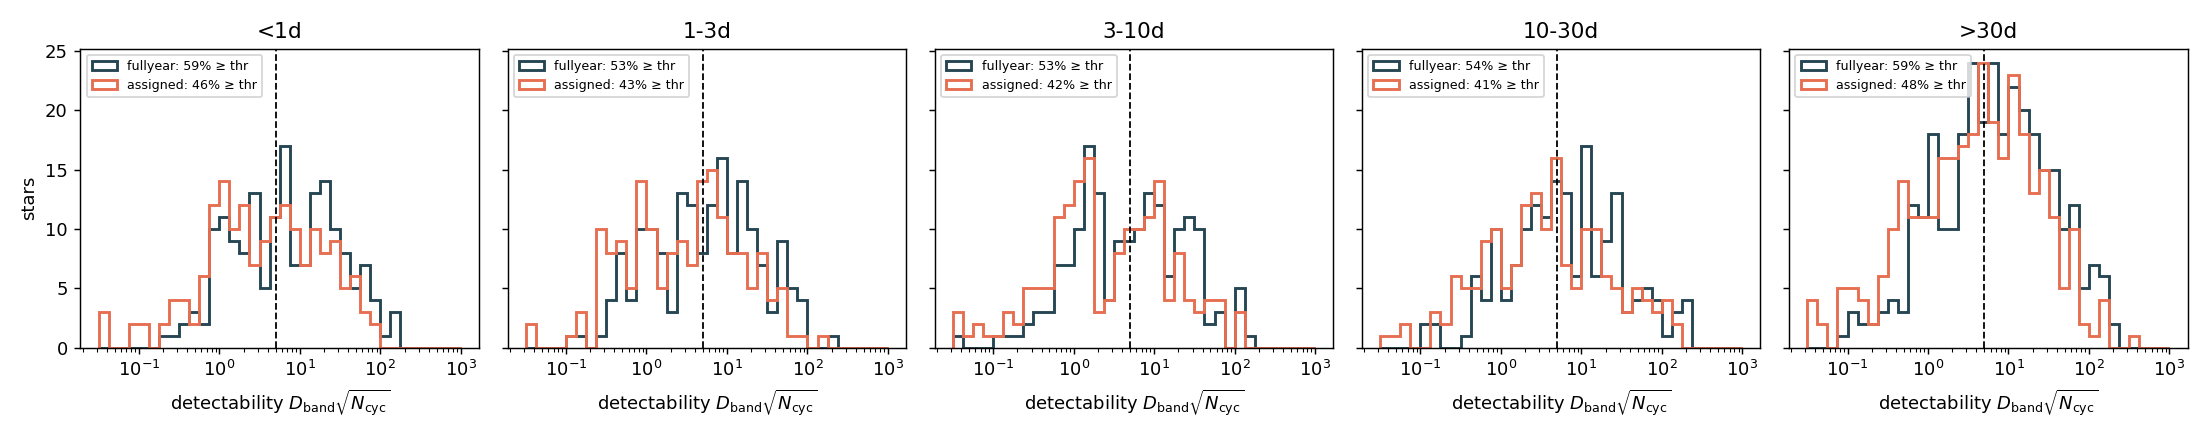

In [4]:
display(Image(A.FIG / 'detectability_distributions.png'))

## Outcome fractions vs detectability per period bin (threshold marked)

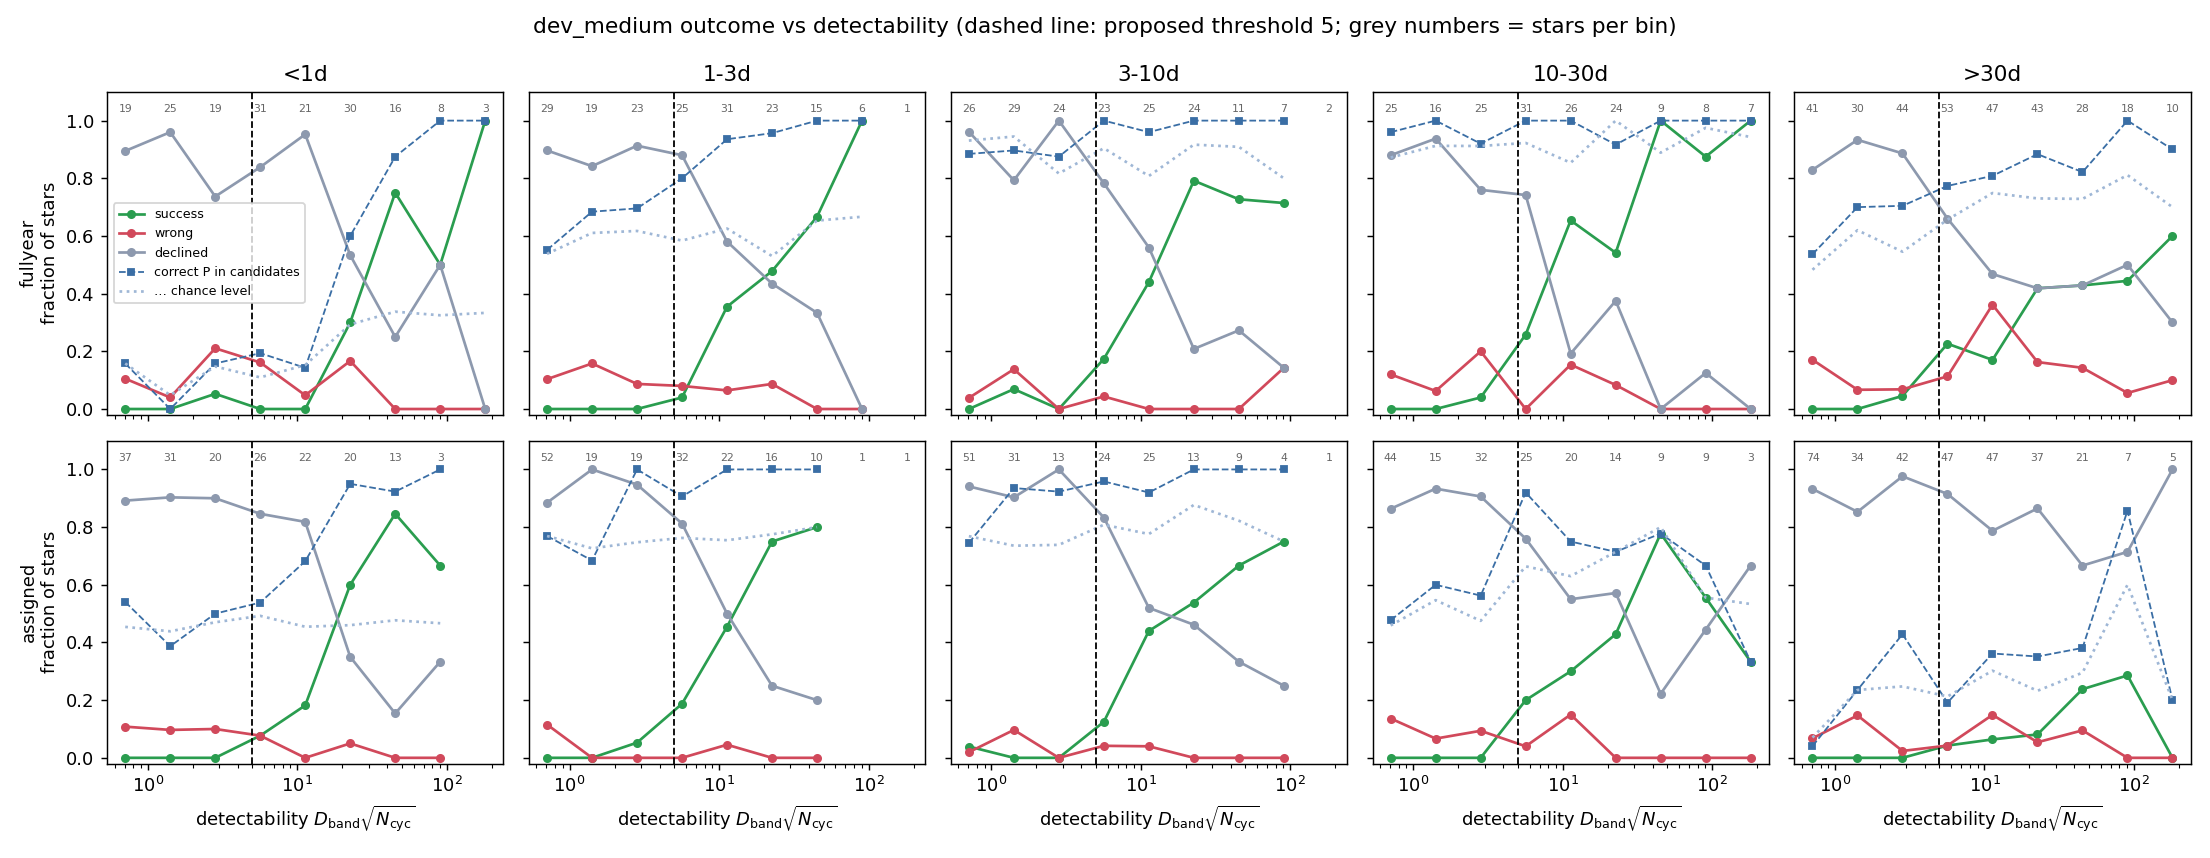

In [5]:
display(Image(A.FIG / 'outcome_vs_detectability.png'))

## Threshold trade-off

fullyear


,threshold,frac_detectable,n_detectable,success_det,wrong_det,declined_det,ceiling_det,success_kept,success_below,wrong_below,ceiling_excess_below
0,3,0.662,662,0.367,0.103,0.530,0.826,0.980,0.015,0.101,0.040
1,4,0.606,606,0.399,0.101,0.500,0.835,0.976,0.015,0.104,0.043
2,5,0.560,560,0.429,0.098,0.473,0.845,0.968,0.018,0.107,0.046
3,6,0.521,521,0.455,0.094,0.451,0.848,0.956,0.023,0.111,0.057
4,8,0.443,443,0.490,0.106,0.404,0.869,0.875,0.056,0.099,0.064
5,10,0.394,394,0.520,0.099,0.381,0.881,0.827,0.071,0.104,0.070


assigned


,threshold,frac_detectable,n_detectable,success_det,wrong_det,declined_det,ceiling_det,success_kept,success_below,wrong_below,ceiling_excess_below
0,3,0.541,541,0.268,0.048,0.684,0.677,0.980,0.007,0.081,0.034
1,4,0.486,486,0.298,0.047,0.654,0.681,0.980,0.006,0.078,0.046
2,5,0.444,444,0.322,0.050,0.628,0.694,0.966,0.009,0.074,0.046
3,6,0.398,398,0.354,0.050,0.595,0.709,0.953,0.012,0.071,0.045
4,8,0.332,332,0.383,0.051,0.566,0.702,0.858,0.031,0.069,0.057
5,10,0.290,290,0.403,0.041,0.555,0.714,0.791,0.044,0.072,0.061


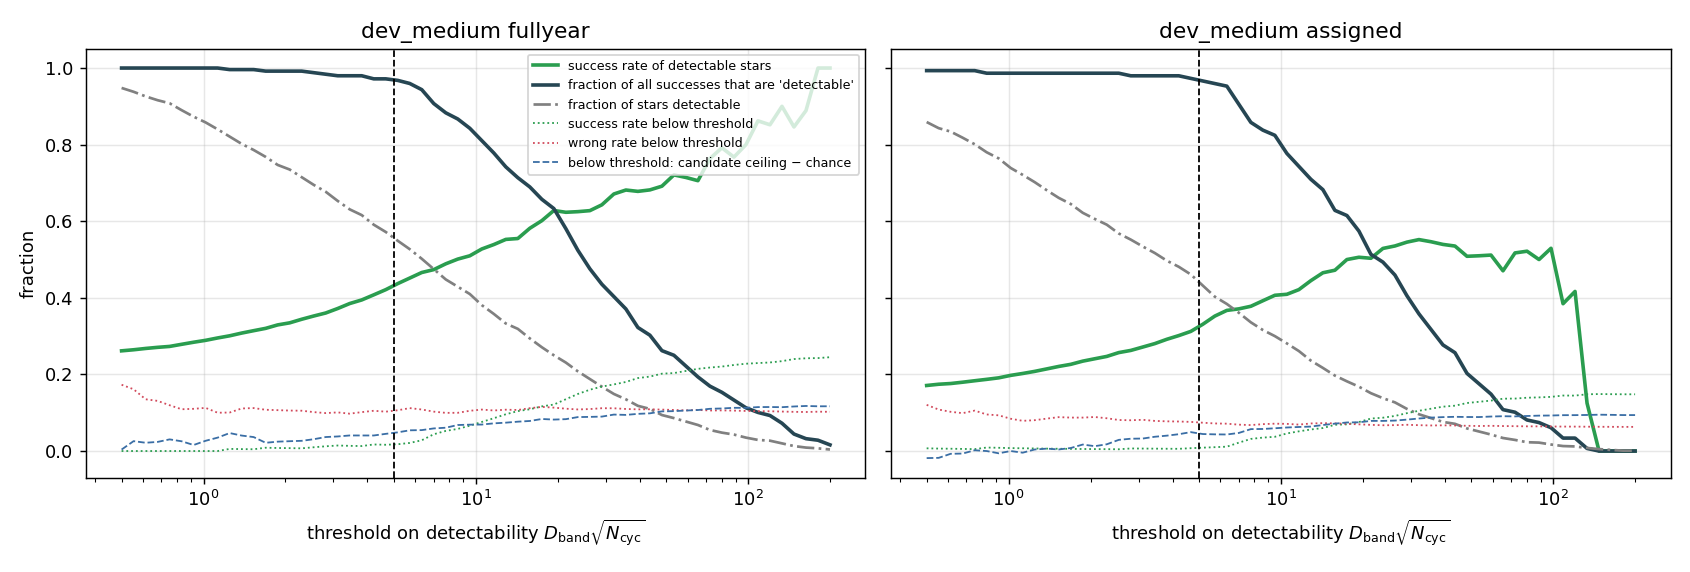

In [6]:
for m in A.MODES:
    s = pd.read_csv(A.DATA / f'threshold_scan_{m}.csv')
    print(m); display(A.scan_thresholds(J[m], [3, 4, 5, 6, 8, 10]).round(3))
display(Image(A.FIG / 'threshold_tradeoff.png'))

## Metrics on the detectable subset, per period bin

In [7]:
M = json.loads((A.REPORT / 'metrics.json').read_text())
for m in A.MODES:
    for sub in ['all', 'detectable', 'undetectable', 'detectable_quiet', 'undetectable_quiet', 'detectable_quiet_searchable']:
        print(m, sub); display(pd.DataFrame(M[m][sub]).T.round(3))

fullyear all


,n,success,wrong,declined,ceiling_any_candidate,ceiling_chance
overall,1000.0,0.248,0.102,0.650,0.764,0.647
<1d,172.0,0.169,0.105,0.727,0.337,0.183
1-3d,172.0,0.233,0.081,0.686,0.802,0.592
3-10d,171.0,0.298,0.041,0.661,0.942,0.885
10-30d,171.0,0.363,0.088,0.550,0.971,0.915
>30d,314.0,0.210,0.153,0.637,0.768,0.655


fullyear detectable


,n,success,wrong,declined,ceiling_any_candidate,ceiling_chance
overall,560.0,0.429,0.098,0.473,0.845,0.672
<1d,101.0,0.277,0.079,0.644,0.495,0.236
1-3d,91.0,0.440,0.044,0.516,0.956,0.589
3-10d,90.0,0.544,0.022,0.433,0.989,0.869
10-30d,93.0,0.645,0.065,0.290,0.978,0.927
>30d,185.0,0.341,0.189,0.470,0.843,0.726


fullyear undetectable


,n,success,wrong,declined,ceiling_any_candidate,ceiling_chance
overall,440.0,0.018,0.107,0.875,0.661,0.615
<1d,71.0,0.014,0.141,0.845,0.113,0.107
1-3d,81.0,0.000,0.123,0.877,0.630,0.595
3-10d,81.0,0.025,0.062,0.914,0.889,0.904
10-30d,78.0,0.026,0.115,0.859,0.962,0.900
>30d,129.0,0.023,0.101,0.876,0.659,0.553


... (14 outputs left out)

assigned undetectable_quiet


,n,success,wrong,declined,ceiling_any_candidate,ceiling_chance
overall,471.0,0.006,0.023,0.970,0.524,0.475
<1d,77.0,0.000,0.026,0.974,0.455,0.462
1-3d,83.0,0.000,0.012,0.988,0.771,0.728
3-10d,85.0,0.012,0.000,0.988,0.835,0.748
10-30d,87.0,0.023,0.034,0.943,0.552,0.474
>30d,139.0,0.000,0.036,0.964,0.209,0.164


assigned detectable_quiet_searchable


,n,success,wrong,declined,ceiling_any_candidate,ceiling_chance
overall,276.0,0.449,0.029,0.522,0.917,0.677
<1d,68.0,0.412,0.015,0.574,0.809,0.453
1-3d,62.0,0.500,0.000,0.500,0.984,0.771
3-10d,61.0,0.443,0.016,0.541,0.967,0.810
10-30d,44.0,0.568,0.023,0.409,0.932,0.818
>30d,41.0,0.317,0.122,0.561,0.902,0.556


## Outcome × noise class × detectable (full-year)

In [8]:
x = J['fullyear'].assign(detectable=lambda d: d[A.STAT] >= THR)
pd.crosstab([x.detectable, x.noise_classification], x.outcome3, margins=True)

outcome3                                    declined  success  wrong   All
detectable noise_classification                                           
False      contamination_candidate_crowded         2        2     11    15
           contamination_known_variable           10        2     22    34
           periodic_low_amplitude                  9        0      0     9
           quiet                                 364        4      6   374
           source_specific_unexplained             0        0      8     8
True       contamination_candidate_crowded         8        4      7    19
           contamination_known_variable           13       12      7    32
           misclassified_star                      2        0      0     2
           periodic_low_amplitude                  7        3      3    13
           quiet                                 233      212     31   476
           source_specific_unexplained             2        9      7    18
All                                              650      248    102  1000

## Example stars

example_borderline.png


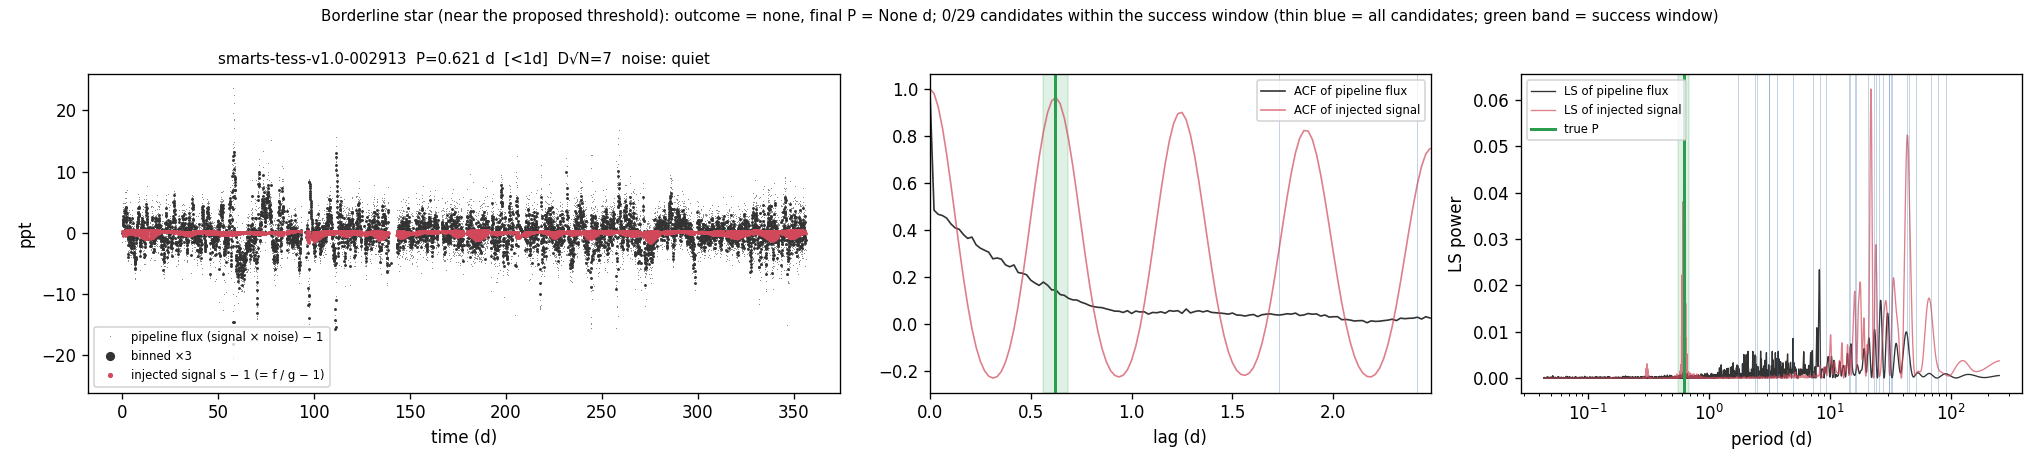

example_detectable_declined.png


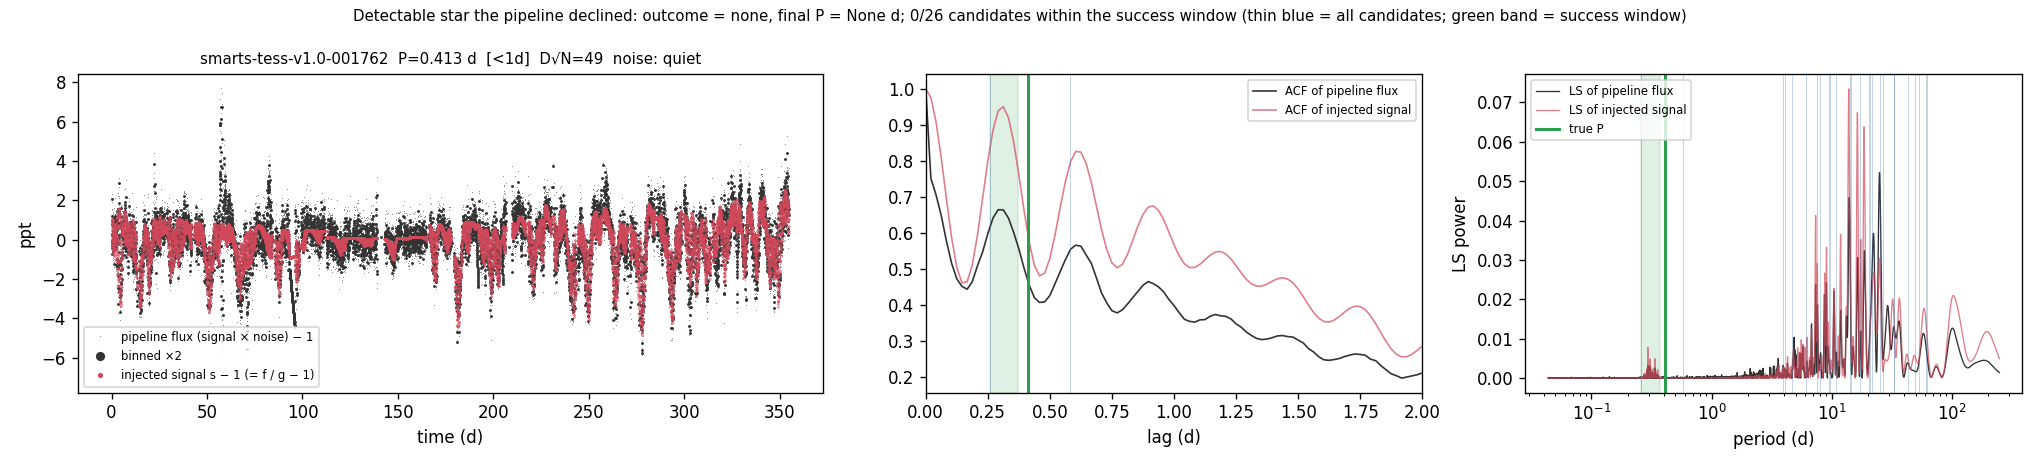

example_undetectable_wrong.png


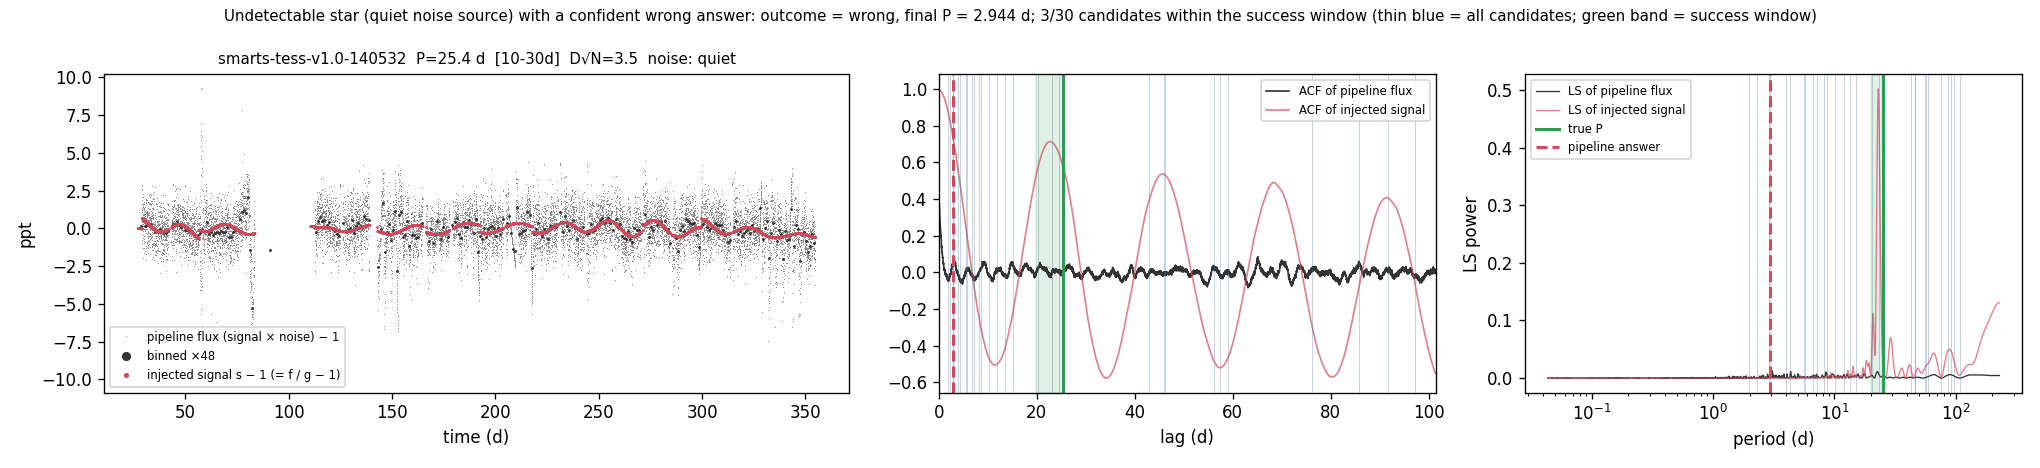

example_undetectable_wrong_contaminated.png


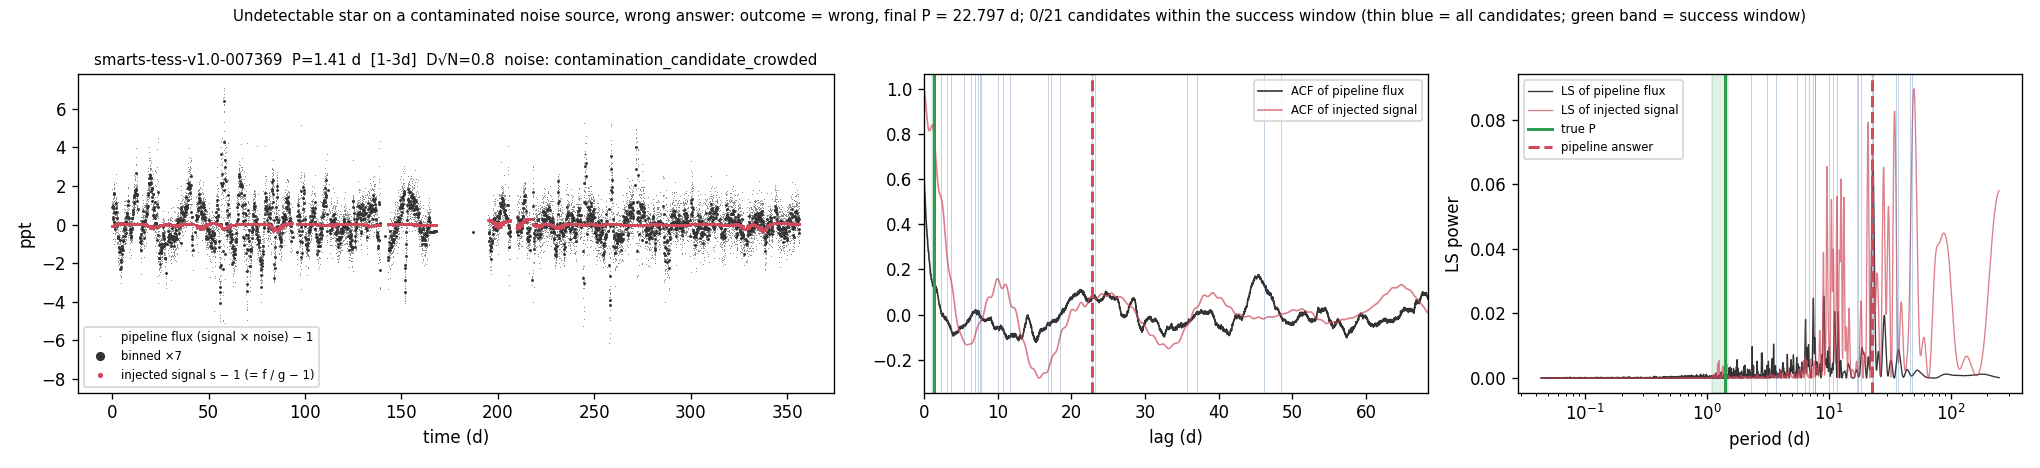

In [9]:
for p in sorted(A.FIG.glob('example_*.png')): print(p.name); display(Image(p))

## Robustness: statistic computed with stack half A vs half B (40 non-member stars)

In [10]:
h = pd.read_csv(A.DATA / 'stack_half_check.csv'); (h.snr_A / h.snr_B).describe()

count    40.000000
mean      1.001843
std       0.020824
min       0.945049
25%       0.999211
50%       1.000171
75%       1.002643
max       1.091007
dtype: float64